# Tema 4 - Retele Markov
Moga Eduard, E3

## Ex 1

**a)** A ⊥ C | B inseamna ca daca stim B, C nu mai aduce nicio informatie despre A:

P(a, c | b) = P(a | b) * P(c | b)

Singurul drum de la A la C trece prin B, deci B blocheaza influenta.

**b)** Independenta => factorizare

P(a,b,c) = P(a,c | b) * P(b)
         = P(a | b) * P(c | b) * P(b)      (din independenta)
         = P(a,b) * P(c | b)

Aleg phi_AB(a,b) = P(a,b), phi_BC(b,c) = P(c | b), Z = 1.
Sunt strict pozitive pentru ca P > 0.

**c)** Factorizare => independenta

P(a,b,c) = 1/Z * phi_AB(a,b) * phi_BC(b,c)

Notez alfa(b) = suma dupa a din phi_AB(a,b), beta(b) = suma dupa c din phi_BC(b,c).

P(b) = 1/Z * alfa(b) * beta(b)     (sumele se despart, fiecare factor depinde doar de partea lui)

P(a,c | b) = P(a,b,c) / P(b) = phi_AB(a,b) * phi_BC(b,c) / (alfa(b) * beta(b))

P(a | b) = phi_AB(a,b) / alfa(b)
P(c | b) = phi_BC(b,c) / beta(b)

Inmultite dau exact P(a,c | b), deci A ⊥ C | B.
Pozitivitatea ne trebuie ca sa nu impartim la 0.

Concluzie: pe A - B - C, independenta conditionata <=> factorizarea pe muchii (Hammersley-Clifford pentru 3 noduri).

In [25]:
import itertools
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteMarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor
from pgmpy.inference import BeliefPropagation, VariableElimination

## Ex 2

In [26]:
stari = ["Soare", "Ploaie", "Nori"]
statii = ["S1", "S2", "S3", "S4", "S5"]
muchii = [("S1", "S2"), ("S2", "S3"), ("S2", "S4"), ("S4", "S5")]
p = [0.5, 0.3, 0.2]
Psi = np.array([[0.7, 0.2, 0.1],
                [0.2, 0.6, 0.2],
                [0.1, 0.3, 0.6]])

### a)

S1 ['S2']
S2 ['S1', 'S3', 'S4']
S3 ['S2']
S4 ['S2', 'S5']
S5 ['S4']
arbore: True


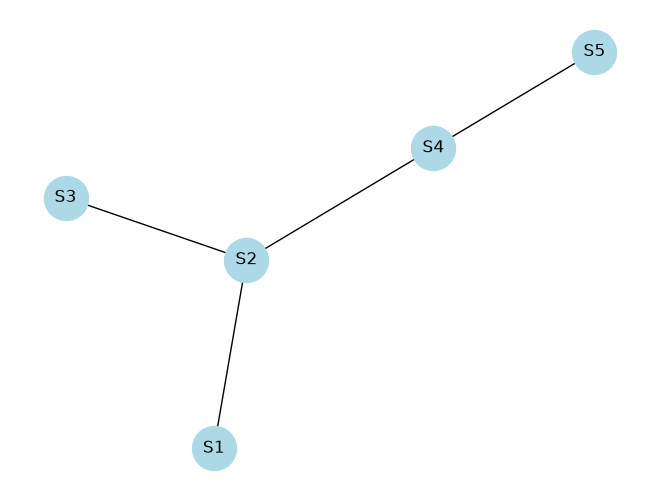

In [27]:
G = nx.Graph()
G.add_edges_from(muchii)

for s in statii:
    print(s, list(G.neighbors(s)))

print("arbore:", nx.is_tree(G))

nx.draw(G, with_labels=True, node_color="lightblue", node_size=1000)
plt.show()

### b)

In [28]:
model = DiscreteMarkovNetwork()
model.add_edges_from(muchii)

for s in statii:
    model.add_factors(DiscreteFactor([s], [3], p, state_names={s: stari}))

for a, b in muchii:
    model.add_factors(DiscreteFactor([a, b], [3, 3], Psi.flatten(), state_names={a: stari, b: stari}))

print(model.check_model())

True


### c)
P(s1,...,s5) = 1/Z * phi1(s1) * ... * phi5(s5) * Psi(s1,s2) * Psi(s2,s3) * Psi(s2,s4) * Psi(s4,s5)

Z = suma peste toate cele 3^5 = 243 de configuratii.

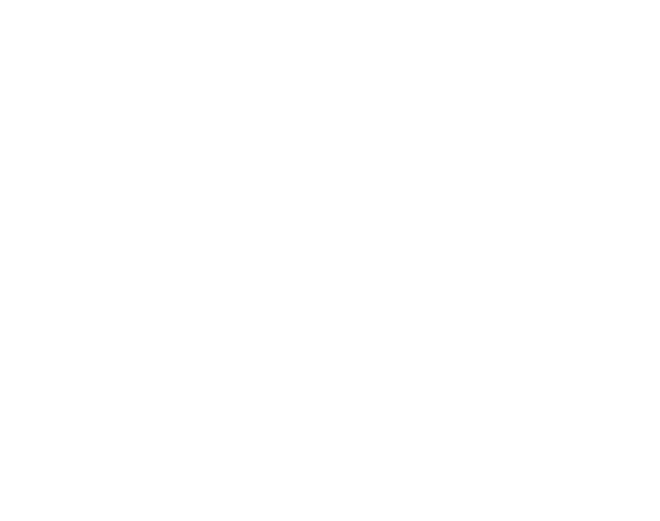

In [29]:
nx.draw(model, with_labels=True, node_color="orange", node_size=1000)
plt.title("graful modelului")
plt.show()

### d) Observ S1 = Ploaie, S5 = Nori

In [30]:
bp = BeliefPropagation(model)
evidenta = {"S1": "Ploaie", "S5": "Nori"}

for s in ["S2", "S3", "S4"]:
    print(bp.query([s], evidence=evidenta, show_progress=False))

+------------+-----------+
| S2         |   phi(S2) |
+============+===========+
| S2(Soare)  |    0.3357 |
+------------+-----------+
| S2(Ploaie) |    0.5335 |
+------------+-----------+
| S2(Nori)   |    0.1307 |
+------------+-----------+
+------------+-----------+
| S3         |   phi(S3) |
+============+===========+
| S3(Soare)  |    0.4651 |
+------------+-----------+
| S3(Ploaie) |    0.3922 |
+------------+-----------+
| S3(Nori)   |    0.1426 |
+------------+-----------+
+------------+-----------+
| S4         |   phi(S4) |
+============+===========+
| S4(Soare)  |    0.2823 |
+------------+-----------+
| S4(Ploaie) |    0.3674 |
+------------+-----------+
| S4(Nori)   |    0.3503 |
+------------+-----------+


### e)

In [31]:
map_comun = bp.map_query(["S2", "S3", "S4"], evidence=evidenta, show_progress=False)
print("MAP comun:", map_comun)

MAP comun: {'S2': 'Soare', 'S4': 'Soare', 'S3': 'Soare'}


In [32]:
def prob(config):
    rez = 1
    for s in statii:
        rez *= p[config[s]]
    for a, b in muchii:
        rez *= Psi[config[a], config[b]]
    return rez

Z = 0
for c in itertools.product(range(3), repeat=3):
    Z += prob({"S1": 1, "S2": c[0], "S3": c[1], "S4": c[2], "S5": 2})

def p_scenariu(s2, s3, s4):
    i = stari.index
    return prob({"S1": 1, "S2": i(s2), "S3": i(s3), "S4": i(s4), "S5": 2}) / Z

print("MAP comun     (Soare, Soare, Soare):  ", p_scenariu("Soare", "Soare", "Soare"))
print("Max marginale (Ploaie, Soare, Ploaie):", p_scenariu("Ploaie", "Soare", "Ploaie"))

MAP comun     (Soare, Soare, Soare):   0.16210136297472538
Max marginale (Ploaie, Soare, Ploaie): 0.08574831282254862


Nu coincid. Daca iau fiecare statie separat obtin (Ploaie, Soare, Ploaie), dar cel mai probabil scenariu complet e Soare peste tot, cu probabilitate aproape dubla.

Marginala aduna peste multe configuratii, iar Ploaie la S2 apare in multe configuratii ok. MAP comun cauta o singura configuratie cea mai buna, iar Soare-Soare are cel mai mare potential (0.7).

## Ex 3

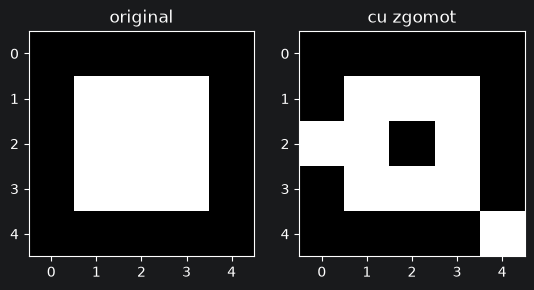

In [33]:
N = 5
original = np.zeros((N, N), dtype=int)
original[1:4, 1:4] = 1

rng = np.random.default_rng(6)
y = original.copy()
pozitii = rng.choice(N * N, 3, replace=False)
for k in pozitii:
    y[k // N, k % N] = 1 - y[k // N, k % N]

plt.subplot(1, 2, 1); plt.imshow(original, cmap="gray"); plt.title("original")
plt.subplot(1, 2, 2); plt.imshow(y, cmap="gray"); plt.title("cu zgomot")
plt.show()

### c)
Fiecare pixel e un nod legat de vecinii sus/jos/stanga/dreapta.

E(x) = lambda * suma (x_i - y_i)^2 + suma pe muchii (x_i - x_j)^2

- primul termen: vrem sa ramanem aproape de ce am observat
- al doilea: vrem ca vecinii sa fie la fel (netezire)
- lambda: cat conteaza observatia fata de netezire

MAP = energia minima.

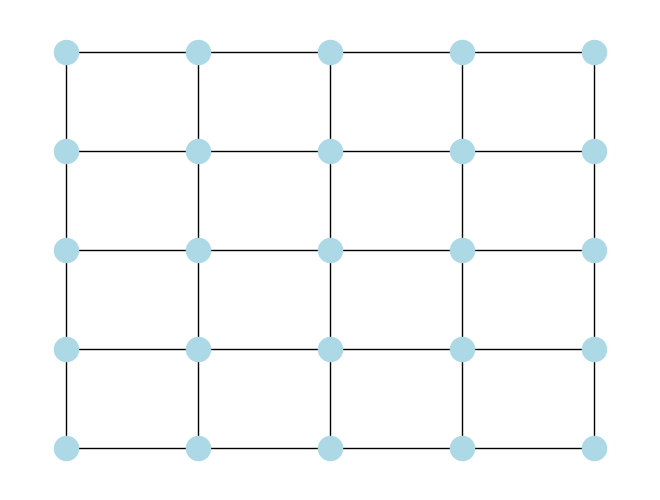

In [34]:
def vecini(i, j):
    v = []
    for a, b in [(i-1, j), (i+1, j), (i, j-1), (i, j+1)]:
        if 0 <= a < N and 0 <= b < N:
            v.append((a, b))
    return v

muchii_img = []
for i in range(N):
    for j in range(N):
        for a, b in vecini(i, j):
            if (a, b) > (i, j):
                muchii_img.append(((i, j), (a, b)))

G_img = nx.Graph(muchii_img)
nx.draw(G_img, pos={(i, j): (j, -i) for i in range(N) for j in range(N)}, node_color="lightblue", node_size=300)
plt.show()

def energie(x, lam):
    e = lam * np.sum((x - y) ** 2)
    for u, v in muchii_img:
        e += (x[u] - x[v]) ** 2
    return e

### d) MAP exact cu pgmpy si ICM

In [35]:
def nume(i, j):
    return f"x{i}{j}"

def map_exact(lam):
    m = DiscreteMarkovNetwork()
    m.add_edges_from([(nume(*u), nume(*v)) for u, v in muchii_img])
    for i in range(N):
        for j in range(N):
            m.add_factors(DiscreteFactor([nume(i, j)], [2], [np.exp(-lam * (0 - y[i, j]) ** 2),
                                                             np.exp(-lam * (1 - y[i, j]) ** 2)]))
    for u, v in muchii_img:
        m.add_factors(DiscreteFactor([nume(*u), nume(*v)], [2, 2], [1, np.exp(-1), np.exp(-1), 1]))
    rez = VariableElimination(m).map_query(show_progress=False)
    x = np.zeros((N, N), dtype=int)
    for i in range(N):
        for j in range(N):
            x[i, j] = rez[nume(i, j)]
    return x

def icm(lam):
    x = y.copy()
    schimbat = True
    while schimbat:
        schimbat = False
        for i in range(N):
            for j in range(N):
                e0 = lam * (0 - y[i, j]) ** 2 + sum((0 - x[a, b]) ** 2 for a, b in vecini(i, j))
                e1 = lam * (1 - y[i, j]) ** 2 + sum((1 - x[a, b]) ** 2 for a, b in vecini(i, j))
                if e0 < e1:
                    nou = 0
                elif e1 < e0:
                    nou = 1
                else:
                    nou = x[i, j]
                if nou != x[i, j]:
                    x[i, j] = nou
                    schimbat = True
    return x

### e)

lambda=0.3: ICM gresiti=11, E=8.0 | exact gresiti=9, E=3.0


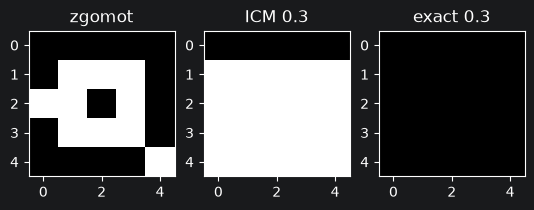

lambda=1: ICM gresiti=1, E=15.0 | exact gresiti=9, E=10.0


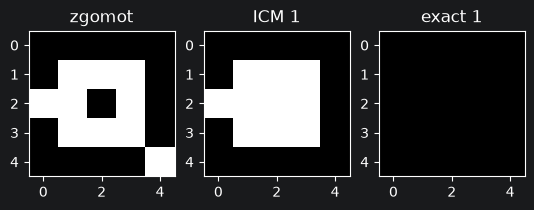

lambda=1.8: ICM gresiti=1, E=16.6 | exact gresiti=1, E=16.6


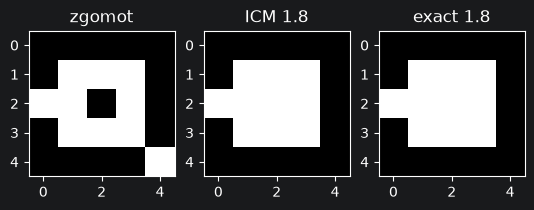

lambda=3: ICM gresiti=2, E=18.0 | exact gresiti=2, E=18.0


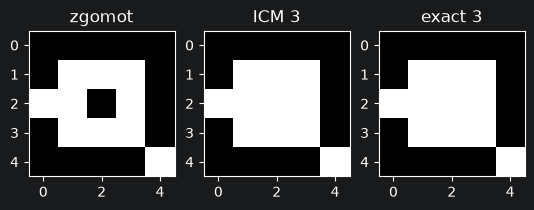

In [36]:
for lam in [0.3, 1, 1.8, 3]:
    x_icm = icm(lam)
    x_ex = map_exact(lam)
    print(f"lambda={lam}: ICM gresiti={np.sum(x_icm != original)}, E={energie(x_icm, lam):.1f} | "
          f"exact gresiti={np.sum(x_ex != original)}, E={energie(x_ex, lam):.1f}")
    plt.subplot(1, 3, 1); plt.imshow(y, cmap="gray"); plt.title("zgomot")
    plt.subplot(1, 3, 2); plt.imshow(x_icm, cmap="gray"); plt.title(f"ICM {lam}")
    plt.subplot(1, 3, 3); plt.imshow(x_ex, cmap="gray"); plt.title(f"exact {lam}")
    plt.show()

Un pixel se inverseaza daca lambda < (vecini diferiti - vecini egali).

- lambda mic (0.3, 1): castiga netezirea, MAP exact sterge tot patratul (imaginea neagra are energie mai mica)
- lambda 1.8: compromisul bun, MAP exact pastreaza patratul si ramane un singur pixel gresit
- lambda 3: castiga observatia, se pastreaza si zgomotul

La lambda = 1 ICM a gresit un singur pixel, desi exact a sters tot patratul. ICM s-a oprit intr-un minim local, care intamplator e aproape de imaginea adevarata. Deci ICM nu garanteaza MAP-ul global, iar MAP-ul modelului nu e neaparat imaginea reala daca lambda e ales prost.